# Demo 1: Introduction to GAMs with GEFCom14 load data (Python / pymgcv)

This notebook is the Python version of [`R_demos/1_Intro_Gefcom14.R`](../R_demos/1_Intro_Gefcom14.R).
It uses [pymgcv](https://smoothforge.github.io/pymgcv/), a Python interface to the R package `mgcv`.

This demo uses The dataset `gefcom_small` has one row per day from 2005 to 2011 (2522 days), taken from the
GEFCom 2014 load forecasting competition. Each variable, and how we use it in the models:

- **`NetDemand`**: the electricity net demand on that day. This is the **response** we want
  to predict.
- **`NetDemand.24`**: the demand on the previous day (a lag of 24 hours). Demand is very
  persistent, so yesterday's value is a strong predictor. Its effect is close to linear, so
  we model it as a **linear** term, `L("NetDemand.24")`.
- **`Dow`**: day of the week, coded `"0"` (Sunday) to `"6"` (Saturday). It's a categorical
  variable: demand is lower at weekends, but there is no natural ordering between days. We
  convert it to a pandas `category` and include it as a **factor**, `L("Dow")`, which gives
  each day its own offset.
- **`Trend`**: time, rescaled from 0 (first day) to 1 (last day). It captures slow long-term
  changes in demand (e.g. economic growth, efficiency). We model it as a **linear** trend,
  `L("Trend")`.
- **`Posan`**: position in the year, from 0 (1 January) to 1
  (31 December). It captures the yearly seasonality. Because 31 December and 1 January are
  neighbours, we use a **cyclic smooth**, `S("Posan", bs=CubicSpline(cyclic=True))`, whose
  two ends join up.
- **`wM`**: temperature (in °C), averaged over the weather stations. Demand goes up both
  when it's cold (heating) and when it's hot (air conditioning), so the effect is
  **non-linear**. fit1 treats it as linear, and we then switch to a **smooth**, `S("wM")`.
- **`wM_s95`**: an exponentially smoothed version of `wM` (smoothing factor 0.95), i.e. a
  weighted average of recent temperatures. Buildings heat up and cool down slowly, so demand
  also depends on past temperatures, not only today's. Like `wM`, it moves from a linear
  term to a **smooth**, `S("wM_s95")`.
- **`Year`**: calendar year. It's not used in the models, only to split the data into a
  training set (2005–2010) and a test set (2011).

The demo shows how to model the data using GAM models. We model the daily
electricity net demand (`NetDemand`) from the GEFCom 2014 competition and grow
the model step by step. All three models share the same terms and differ only in
how the temperature variables `wM` and `wM_s95` enter the model:

| Model | `NetDemand.24`, `Dow`, `Trend` | `wM` | `wM_s95` | `Posan` |
|---|---|---|---|---|
| **fit1** | linear `L(...)` | **linear** `L("wM")` | **linear** `L("wM_s95")` | cyclic smooth |
| **fit2** | linear `L(...)` | **smooth** `S("wM")` | **smooth** `S("wM_s95")` | cyclic smooth |
| **fit3** | linear `L(...)` | **smooth, larger basis** `S("wM", k=15)` | smooth `S("wM_s95")` | cyclic smooth |

Models are trained on the data before 2011 and tested on 2011.

## The variables



In [22]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

import pymgcv.plot as gplt
from pymgcv.basis_functions import CubicSpline
from pymgcv.gam import GAM
from pymgcv.terms import L, S
from pymgcv.utils import load_rdata_dataframe_from_url

## Load the data

In R the dataset comes from the `testGam` package (`data("gefcom_small")`). In Python we
download the same `.rda` file from GitHub.

R turns the character column `Dow` (day of the week) into a factor automatically. pymgcv
doesn't, so we convert it to a pandas `category`.

In [23]:
DATA_URL = "https://raw.githubusercontent.com/mfasiolo/testGam/master/data/gefcom_small.rda"

data = load_rdata_dataframe_from_url(DATA_URL)
data["Dow"] = data["Dow"].astype("category")
data.head()

,Year,NetDemand,wM,Posan,Trend,Dow,wM_s95,NetDemand.24
1,2005,2.889407,16.388889,0.00137,0.000000,6,8.236849,2.889407
2,2005,2.543342,17.361111,0.00411,0.000396,0,9.933947,2.889407
3,2005,2.446159,18.888889,0.00685,0.000792,1,10.794862,2.543342
4,2005,2.190166,21.250000,0.00959,0.001189,2,14.462260,2.446159
5,2005,2.100094,20.833333,0.01233,0.001585,3,16.194613,2.190166


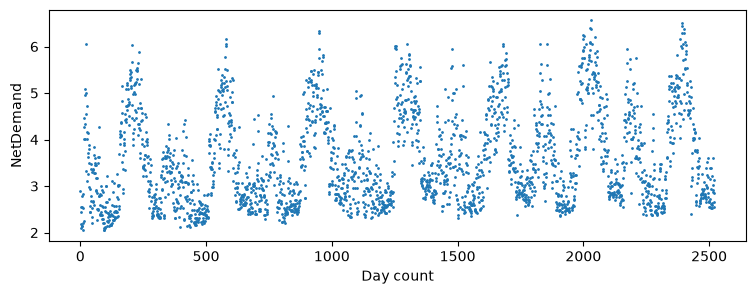

In [24]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(data["NetDemand"].to_numpy(), ".", ms=2)
ax.set(xlabel="Day count", ylabel="NetDemand");

In [25]:
train = data[data["Year"] < 2011].reset_index(drop=True)
test = data[data["Year"] == 2011].reset_index(drop=True)
len(train), len(test)

(2190, 332)

## fit1: linear temperature effects

R equivalent:

```r
gam(NetDemand ~ NetDemand.24 + Dow + Trend + wM + wM_s95 + s(Posan, bs = "cc"), data = train)
```

`L(...)` is a linear (parametric) term and `S(...)` a smooth. `CubicSpline(cyclic=True)` is
`bs = "cc"`, a cyclic cubic spline for the position in the year (`Posan`).

`mgcv::gam()` picks the smoothing parameters with GCV (Generalised Cross-Validation) by default, while pymgcv uses REML (Restricted Maximum Likelihood).
We set `method="GCV.Cp"` to get the same numbers as the R demo.

In [26]:
METHOD = "GCV.Cp"

fit1 = GAM({
    "NetDemand": [
        L("NetDemand.24"),
        L("Dow"),
        L("Trend"),
        L("wM"),
        L("wM_s95"),
        S("Posan", bs=CubicSpline(cyclic=True)),  # s(Posan, bs = "cc")
    ]
})
fit1.fit(train, method=METHOD)

GAM(
  predictors={'NetDemand': [L(varnames=('NetDemand.24',), by=None),
               L(varnames=('Dow',), by=None),
               L(varnames=('Trend',), by=None),
               L(varnames=('wM',), by=None),
               L(varnames=('wM_s95',), by=None),
               S(varnames=('Posan',),
                 by=None,
                 k=None,
                 bs=CubicSpline(shrinkage=False, cyclic=True),
                 id=None,
                 fx=False),
               Intercept(varnames=(), by=None)]},
  family=Gaussian(),
  fit_state=FitState(rgam=mgcv.gam, data=DataFrame),
  add_intercepts=True,
)

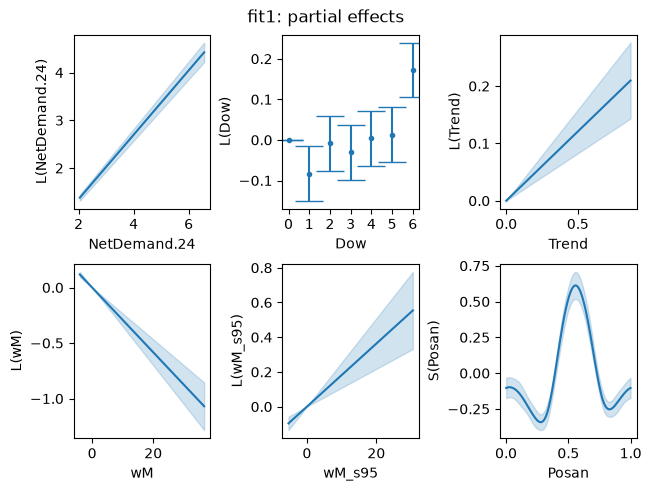

In [27]:
fig, _ = gplt.plot(fit1, ncols=3)
fig.suptitle("fit1: partial effects");

The residuals plotted against temperature (`wM`) are clearly curved, so a linear
temperature effect is not enough.

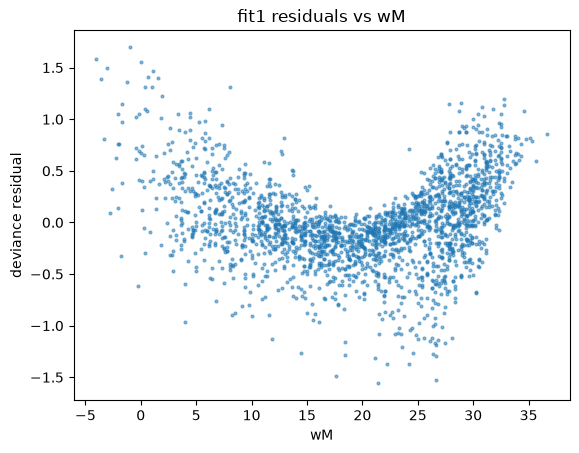

In [28]:
fig, ax = plt.subplots()
ax.scatter(train["wM"], fit1.residuals(), s=4, alpha=0.5)
ax.set(xlabel="wM", ylabel="deviance residual", title="fit1 residuals vs wM");

## fit2: smooth temperature effects

Compared with fit1, `L("wM")` and `L("wM_s95")` become `S("wM")` and `S("wM_s95")`.

R equivalent:

```r
gam(NetDemand ~ NetDemand.24 + Dow + Trend + s(wM) + s(wM_s95) + s(Posan, bs = "cc"), data = train)
```

In [29]:
fit2 = GAM({
    "NetDemand": [
        L("NetDemand.24"),
        L("Dow"),
        L("Trend"),
        S("wM"),     # <- previous version was linear L("wM"), but we now use a smooth term S("wM")
        S("wM_s95"), # <- previous version was linear L("wM_s95"), but we now use a smooth term S("wM_s95")
        S("Posan", bs=CubicSpline(cyclic=True)),
    ]
})
fit2.fit(train, method=METHOD)

GAM(
  predictors={'NetDemand': [L(varnames=('NetDemand.24',), by=None),
               L(varnames=('Dow',), by=None),
               L(varnames=('Trend',), by=None),
               S(varnames=('wM',), by=None, k=None, bs=None, id=None, fx=False),
               S(varnames=('wM_s95',),
                 by=None,
                 k=None,
                 bs=None,
                 id=None,
                 fx=False),
               S(varnames=('Posan',),
                 by=None,
                 k=None,
                 bs=CubicSpline(shrinkage=False, cyclic=True),
                 id=None,
                 fx=False),
               Intercept(varnames=(), by=None)]},
  family=Gaussian(),
  fit_state=FitState(rgam=mgcv.gam, data=DataFrame),
  add_intercepts=True,
)

The new fit uses smooth terms for `wM` and `wM_s95`.

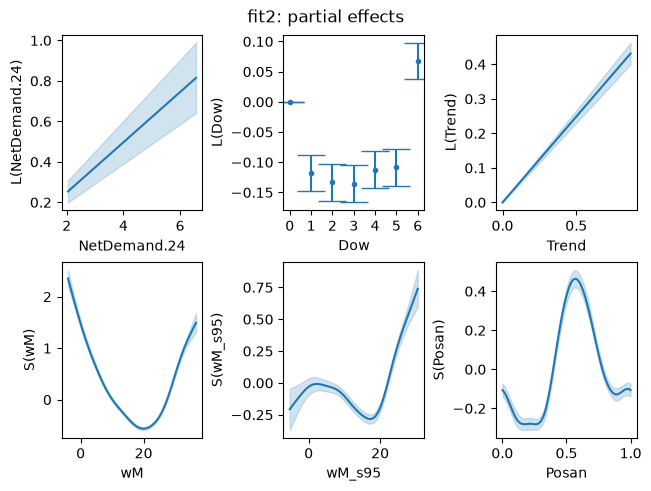

In [30]:
fig, _ = gplt.plot(fit2, ncols=3)
fig.suptitle("fit2: partial effects");

The new marginal residuals for `wM` do not show the previous trend staying around 0 across the `wM` values.

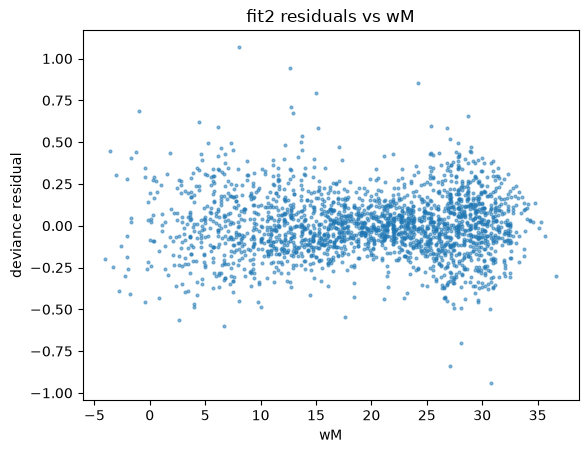

In [31]:
fig, ax = plt.subplots()
ax.scatter(train["wM"], fit2.residuals(), s=4, alpha=0.5)
ax.set(xlabel="wM", ylabel="deviance residual", title="fit2 residuals vs wM");

`check_k` is the basis-dimension check printed by R's `gam.check()`. A low p-value with an
`edf` close to `k'` suggests the basis for that smooth may be too small.

In [32]:
fit2.check_k()

,term,max_edf,edf,k_index,p_value
0,s(wM),9.0,8.524790,0.938984,0.0000
1,s(wM_s95),9.0,7.835844,1.029025,0.9025
2,s(Posan),8.0,7.639076,1.020706,0.8125


## fit3: a larger basis for `wM`

Compared with fit2, the smooth of `wM` gets a larger basis: `S("wM", k=15)` (the default is `k=10`).

R equivalent:

```r
gam(NetDemand ~ NetDemand.24 + Dow + Trend + s(wM, k = 15) + s(wM_s95) + s(Posan, bs = "cc"), data = train)
```

In [33]:
fit3 = GAM({
    "NetDemand": [
        L("NetDemand.24"),
        L("Dow"),
        L("Trend"),
        S("wM", k=15),
        S("wM_s95"),
        S("Posan", bs=CubicSpline(cyclic=True)),
    ]
})
fit3.fit(train, method=METHOD)

for name, model in [("fit1", fit1), ("fit2", fit2), ("fit3", fit3)]:
    print(f"AIC {name}: {model.aic():.3f}")

AIC fit1: 2425.180
AIC fit2: -1081.444
AIC fit3: -1085.873


In [34]:
print(fit3.summary())


Family: gaussian 
Link function: identity 

Formula:
NetDemand ~ NetDemand.24 + Dow + Trend + s(wM, k = 15L) + s(wM_s95) + 
    s(Posan, bs = "cc") + 1

Parametric coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept)   2.98015    0.04752  62.707  < 2e-16 ***
NetDemand.24  0.12405    0.01325   9.361  < 2e-16 ***
Dow1         -0.11977    0.01504  -7.962 2.72e-15 ***
Dow2         -0.13345    0.01523  -8.762  < 2e-16 ***
Dow3         -0.13551    0.01528  -8.868  < 2e-16 ***
Dow4         -0.11411    0.01533  -7.445 1.39e-13 ***
Dow5         -0.10812    0.01528  -7.075 2.01e-12 ***
Dow6          0.06689    0.01521   4.398 1.15e-05 ***
Trend         0.49833    0.01815  27.450  < 2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Approximate significance of smooth terms:
             edf Ref.df      F p-value    
s(wM)     12.887 13.754 361.41  <2e-16 ***
s(wM_s95)  7.868  8.689  44.64  <2e-16 ***
s(Posan)   7.635  8.000  92.03  <2e-16 ***

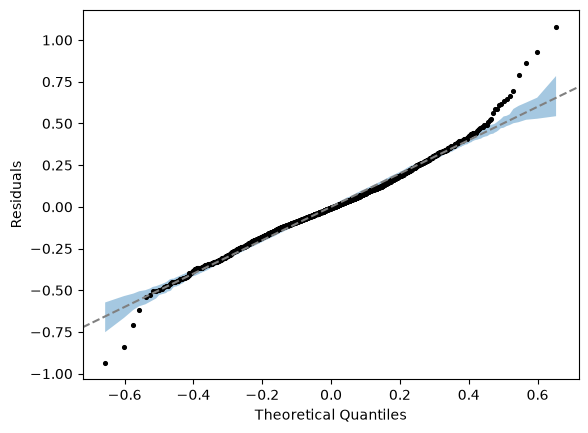

In [35]:
gplt.qq(fit3);

## Predict on 2011

In [36]:
preds = fit3.predict(test)["NetDemand"]
print("First test predictions:", np.round(preds[:6], 5))

rmse = np.sqrt(np.mean((test["NetDemand"].to_numpy() - preds) ** 2))
print(f"Test RMSE (2011): {rmse:.5f}")

First test predictions: [3.42294 3.00093 4.22498 4.03008 3.88636 4.30523]
Test RMSE (2011): 0.29678


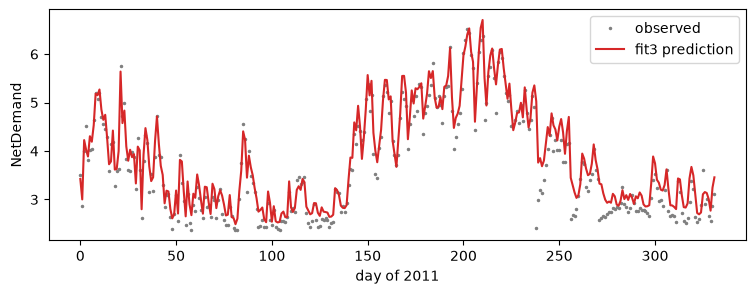

In [37]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(test["NetDemand"].to_numpy(), ".", ms=3, color="grey", label="observed")
ax.plot(preds, color="C3", label="fit3 prediction")
ax.set(xlabel="day of 2011", ylabel="NetDemand")
ax.legend();

# References

Wood S. N. (2017) Generalized additive models: an introduction with R. Second edition. Chapman and Hall/CRC, 2017.